<a href="https://colab.research.google.com/github/oliviaaghamie/beginning-bioinformatics/blob/main/notebooks/Copy_of_Unsupervised_Learning_PCA_and_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Unsupervised learning: discovering structure in gene expression

Do samples group together without telling an algorithm anything other than the gene expression values? (Exploring "latent" structure in the data)

**Sections 0–8 follow the companion slides.** Section 9 adds optional hierarchical clustering and stability exercises.

By the end, you should be able to explain what PCA preserves, how k-means minimizes an objective without labels, and why a cluster needs biological validation.

**How to use:** Upload this file in Google Colab. Use a CPU runtime. Run cells in order; pause at each **Predict** and **Explain** prompt.

**Your name:** Olivia Aghamie


**Student ID:** 1002095139

This is exploratory analysis of one dataset, so we fit on all samples. If PCA or clustering becomes part of a predictive pipeline, fit preprocessing on training data only and evaluate on independent samples.

## 0. Setup
Colab includes the packages used here. This cell prints versions for reproducibility. Random seeds make the examples repeatable, although numerical signs and cluster numbers can vary across versions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, scipy
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
from IPython.display import display
from pathlib import Path
import json

print("NumPy", np.__version__, "scikit-learn", sklearn.__version__, "SciPy", scipy.__version__)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
COLORS = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
OUT = Path('unsupervised_outputs'); OUT.mkdir(exist_ok=True)

def finish(name):
    plt.tight_layout()
    plt.savefig(OUT / (name + '.png'), dpi=160, bbox_inches='tight')
    plt.show()

def scatter_groups(ax, points, labels=None, title='', axis_labels=('PC1', 'PC2')):
    if labels is None:
        ax.scatter(points[:, 0], points[:, 1], color=COLORS[0], s=30, alpha=.8)
    else:
        for i, label in enumerate(np.unique(labels)):
            take = np.asarray(labels) == label
            ax.scatter(points[take, 0], points[take, 1], color=COLORS[i % len(COLORS)], s=30, alpha=.8, label=str(label))
        ax.legend(fontsize=9)
    ax.set(xlabel=axis_labels[0], ylabel=axis_labels[1], title=title)

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass
try:
    import ipywidgets as widgets
    HAVE_WIDGETS = True
except ImportError:
    HAVE_WIDGETS = False
    print('Sliders unavailable: use the function calls provided below.')

NumPy 2.1.3 scikit-learn 1.6.1 SciPy 1.16.3


## 1. Samples, features, and hidden (i.e. latent) structure
Imagine that we measured expression of 60 genes in tumor biopsies from 120 patients with the same cancer diagnosis. We want to determine whether their tumors share one expression pattern or contain distinct molecular subtypes – which may indicate for different treatment regimes.

**Simulated data:** Each row is one biological sample. Each column is one gene. The simulated values mimic normalized, log-transformed gene expression, with a different baseline expression level for each gene and random variation among samples. We simulate three biological states, each with an elevated 10-gene "module". Another 30 genes contain noise only.

We retain state labels as **metadata for later interpretation**, but never pass them into PCA or k-means. Knowing how the simulation was generated lets us check the methods, not train them.

**Predict:**
* What could make two samples close in gene-expression space?
* Does proximity prove a shared cancer subtype?

,Gene_01,Gene_02,Gene_03,Gene_04,Gene_05,Gene_06
Sample_001,10.03,6.12,7.27,8.54,7.54,8.40
Sample_002,6.67,4.89,6.63,6.29,5.43,5.44
Sample_003,6.40,6.20,6.98,7.38,5.02,5.59
Sample_004,7.37,6.38,5.91,5.35,5.39,3.49
Sample_005,9.45,8.06,9.51,8.61,7.48,7.76
Sample_006,7.30,7.97,8.15,8.70,7.46,6.48


Matrix shape: (120, 60) (samples, genes)


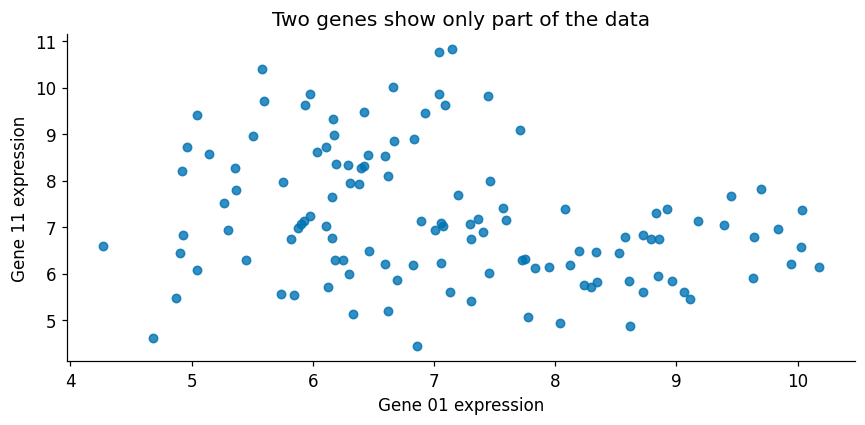

In [2]:
rng = np.random.default_rng(42)
n, p = 120, 60
state = np.repeat(['A', 'B', 'C'], n // 3)
batch = np.tile(np.repeat(['Batch 1', 'Batch 2'], 20), 3)  # balanced within every state
X = rng.normal(6, .5, size=p) + rng.normal(0, .8, size=(n, p))
for g, label in enumerate(['A', 'B', 'C']):
    X[state == label, g*10:(g+1)*10] += 2.5
order = rng.permutation(n)
X, state, batch = X[order], state[order], batch[order]
genes = [f'Gene_{j+1:02d}' for j in range(p)]
samples = [f'Sample_{i+1:03d}' for i in range(n)]
expression = pd.DataFrame(X, index=samples, columns=genes)
metadata = pd.DataFrame({'state': state, 'batch': batch}, index=samples)
display(expression.iloc[:6, :6].round(2))
print('Matrix shape:', expression.shape, '(samples, genes)')
expression.to_csv(OUT / 'simulated_expression.csv')
metadata.to_csv(OUT / 'sample_metadata.csv')
fig, ax = plt.subplots(figsize=(8, 4))
scatter_groups(ax, X[:, [0, 10]], title='Two genes show only part of the data', axis_labels=('Gene 01 expression', 'Gene 11 expression'))
finish('two_genes')

## 2. Scaling defines what “similar” means
Euclidean distance combines differences across genes. A feature with a large numerical spread can dominate.

**Standardization** = center each gene and divide by its standard deviation:

$$z_{ij}=\frac{x_{ij}-\bar{x}_j}{s_j}$$

Here, $i$ is a sample, $j$ is a gene, and $s_j$ is the population standard deviation used by `StandardScaler`.

* **Centering** removes the gene mean.
* **Scaling** changes its weight in distances.
  * **Unit variance** scaling (dividing by the standard deviation) gives noisy genes the same total variance as signal genes.
  * Scaling is a scientific choice, not a universal rule.

For real RNA-seq, first perform suitable sample normalization, low-expression filtering, and a log or variance-stabilizing transformation. Gene standardization is a separate choice and does not replace those steps.

**Predict:** If we multiply one gene by 100, which distances change?

Raw distance, samples 1 and 2: 14.62
After Gene 01 × 100: 336.27
Standardized distance: 12.12
Standardized after × 100: 12.12


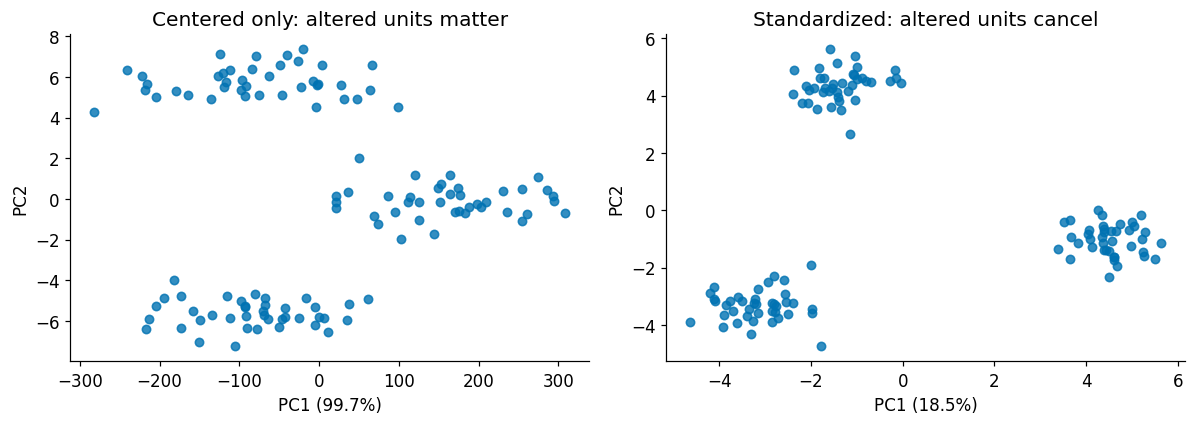

In [3]:
scaler = StandardScaler()
Z = scaler.fit_transform(X)
X_changed = X.copy(); X_changed[:, 0] *= 100
Z_changed = StandardScaler().fit_transform(X_changed)
print('Raw distance, samples 1 and 2:', np.linalg.norm(X[0]-X[1]).round(2))
print('After Gene 01 × 100:', np.linalg.norm(X_changed[0]-X_changed[1]).round(2))
print('Standardized distance:', np.linalg.norm(Z[0]-Z[1]).round(2))
print('Standardized after × 100:', np.linalg.norm(Z_changed[0]-Z_changed[1]).round(2))
assert np.allclose(Z, Z_changed)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, values, title in zip(axes, [X_changed, Z_changed], ['Centered only: altered units matter', 'Standardized: altered units cancel']):
    fit = PCA(n_components=2, svd_solver='full').fit(values)
    coords = fit.transform(values)
    scatter_groups(ax, coords, title=title)
    ax.set_xlabel(f'PC1 ({fit.explained_variance_ratio_[0]:.1%})')
finish('scaling')

## 3. PCA finds directions of variation
**Principal component analysis (PCA)** builds new axes from weighted combinations of the original features. PC1 captures the greatest variance. PC2 captures the greatest remaining variance subject to being perpendicular to PC1.

- A **score** is a sample's coordinate on a PC.
- A **loading** describes a gene's contribution to that axis.
  - Here we use the unit-length component coefficients returned by `components_`
- PCA uses expression measurements only. It does not seek axes that separate known states.

### Rotate a candidate axis
The toy dataset below has just two centered gene measurements. Project the samples onto a line through the origin. Find the angle with the largest variance of projected scores.

### What do the perpendicular lines show?

When we project a sample onto the candidate axis, we replace its original
position with the closest point on that line. That projected point is our
**reconstruction**: an approximation of the original sample using just
one coordinate along the axis.

The perpendicular segment connecting the original point to its projection
shows what this approximation leaves out.

**Reconstruction error** summarizes these differences. In this demonstration,
we square each sample's perpendicular distance and average across samples:

$$
\text{Reconstruction error}
=
\frac{1}{n}\sum_{i=1}^{n}
\left\|\mathbf{x}_i-\hat{\mathbf{x}}_i\right\|^2
$$

Here, $\mathbf{x}_i$ is the original point and $\hat{\mathbf{x}}_i$ is its
projection onto the line.

As you rotate the line:
- A direction that preserves more variation along the line leaves less
  variation in the perpendicular residuals.
- **PC1 is the direction that maximizes projected variance—and minimizes
  squared reconstruction error.**

**Predict:** Which line orientation will give the shortest perpendicular
residuals overall? Will that orientation also give the greatest spread
of projected points along the line?

In [4]:
toy_rng = np.random.default_rng(7)
toy = toy_rng.multivariate_normal([0, 0], [[3, 2.4], [2.4, 3]], size=45)
toy -= toy.mean(axis=0)
toy_fit = PCA(n_components=1, svd_solver='full').fit(toy)
best_angle = float(np.degrees(np.arctan2(*toy_fit.components_[0, ::-1])) % 180)

def projection_demo(angle=45):
    u = np.array([np.cos(np.radians(angle)), np.sin(np.radians(angle))])
    scores = toy @ u
    reconstructed = np.outer(scores, u)
    variance = np.var(scores)
    error = np.mean(np.sum((toy-reconstructed)**2, axis=1))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].scatter(*toy.T, color=COLORS[0], label='Observed')
    axes[0].scatter(*reconstructed.T, color=COLORS[1], s=20, label='Projection')
    for a, b in zip(toy, reconstructed):
        axes[0].plot([a[0], b[0]], [a[1], b[1]], color='gray', alpha=.35)
    axes[0].plot([-5*u[0], 5*u[0]], [-5*u[1], 5*u[1]], color='black')
    axes[0].set(xlim=(-5, 5), ylim=(-5, 5), xlabel='Centered gene 1', ylabel='Centered gene 2', title=f'Axis angle: {angle}°')
    axes[0].set_aspect('equal'); axes[0].legend(fontsize=8)
    angles = np.arange(181)
    variances = [np.var(toy @ np.array([np.cos(np.radians(a)), np.sin(np.radians(a))])) for a in angles]
    axes[1].plot(angles, variances, color=COLORS[0])
    axes[1].scatter([angle], [variance], color=COLORS[1])
    axes[1].set(xlabel='Axis angle (degrees)', ylabel='Projected variance', title=f'Reconstruction error = {error:.2f}')
    plt.tight_layout(); plt.show()
    print(f'Projected variance: {variance:.3f}; PCA optimum angle: {best_angle:.1f}°')

if HAVE_WIDGETS:
    display(widgets.interactive(projection_demo, angle=widgets.IntSlider(value=45, min=0, max=180, step=5, continuous_update=False)))

#### Fallback if widget sliders don't work (or to explore specific angles) uncomment the following lines ####
#projection_demo(45)
#projection_demo(135)

interactive(children=(IntSlider(value=45, continuous_update=False, description='angle', max=180, step=5), Outp…

### PCA on all 60 genes
For centered standardized features, a PC score is a weighted sum:

$$t_{ik}=\sum_{j=1}^{p}z_{ij}v_{jk}$$
* $t_{ik}$: PC score for sample i
* $z_{ij}$: standardized expression of gene j in sample i
* $v_{jk}$: weight (loading coefficient) of gene j in PC k

PCA also minimizes squared reconstruction error for a fixed number of retained orthogonal components. This is an **unsupervised objective**: the target is the original feature matrix, not a phenotype.

Example: If we keep only two PCs, we compress each sample’s 60 expression measurements into two PC scores. PCA finds the two perpendicular axes that let us reconstruct those measurements as accurately as possible, measured by squared error. It does this using expression alone, without knowing the samples’ biological groups or outcomes.

**Explain:** Two samples appear close together on the PC1–PC2 plot. Does that necessarily mean they have similar expression across all 60 genes? What might the plot be leaving out?

PCA gives each sample a position on the plot, but it does not assign samples to groups. Later, we will use clustering to make those assignments.

In [ ]:
pca = PCA(svd_solver='full').fit(Z)
PC = pca.transform(Z)
variance_ratio = pca.explained_variance_ratio_
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
scatter_groups(axes[0], PC[:, :2], title='Samples projected from 60 genes')
axes[0].set(xlabel=f'PC1 ({variance_ratio[0]:.1%})', ylabel=f'PC2 ({variance_ratio[1]:.1%})')
axes[1].plot(np.arange(1, 11), 100*variance_ratio[:10], 'o-', color=COLORS[0], label='Individual PC')
axes[1].plot(np.arange(1, 11), 100*np.cumsum(variance_ratio)[:10], 'o-', color=COLORS[1], label='Cumulative')
axes[1].set(xlabel='Principal component', ylabel='Variance explained (%)', ylim=(0, 100))
axes[1].legend()
finish('pca_and_variance')
print(f'The first two PCs retain {sum(variance_ratio[:2]):.1%} of total variance.')
loadings = pd.DataFrame(pca.components_[:2].T, index=genes, columns=['PC1 coefficient', 'PC2 coefficient'])
display(loadings.reindex(loadings['PC1 coefficient'].abs().sort_values(ascending=False).index).head(8).round(3))
loadings.to_csv(OUT / 'pc_coefficients.csv')

### Explore adding PC3
Each point is the same biological sample in both 2D and 3D plots.
Each PC combines information from all 60 genes.

**COMPARE THE VIEWS:** Drag to rotate the 3D plot; scroll to zoom.

Rotate the 3D plot to approximate each view.
The 2D panels remain fixed as reference projections.
Apparent overlap in one projection can disappear in another.
* Looking down PC3 gives the PC1–PC2 projection.
* Looking down PC2 gives the PC1–PC3 projection.
* Looking down PC1 gives the PC2–PC3 projection.

Does PC3 reveal another group, or mostly variation within groups?

Even in three dimensions some variation will be out of view.


In [5]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

axis_labels = [
    f"PC{i+1} ({variance_ratio[i]:.1%} variance)"
    for i in range(3)
]
sample_names = expression.index.astype(str).tolist()

fig = make_subplots(
    rows=2,
    cols=3,
    specs=[
        [{"type": "scene", "rowspan": 2},
         {"type": "xy"}, {"type": "xy"}],
        [None, {"type": "xy"}, None]
    ],
    column_widths=[0.46, 0.27, 0.27],
    horizontal_spacing=0.08,
    vertical_spacing=0.18,
    subplot_titles=[
        "Rotate to explore",
        "PC1 versus PC2",
        "PC1 versus PC3",
        "PC2 versus PC3"
    ]
)

# Rotatable 3D view.
fig.add_trace(
    go.Scatter3d(
        x=PC[:, 0],
        y=PC[:, 1],
        z=PC[:, 2],
        mode="markers",
        marker=dict(size=4, color="#0072B2", opacity=0.8),
        text=sample_names,
        hovertemplate=(
            "%{text}<br>"
            "PC1: %{x:.2f}<br>"
            "PC2: %{y:.2f}<br>"
            "PC3: %{z:.2f}<extra></extra>"
        ),
        showlegend=False
    ),
    row=1, col=1
)

# Fixed 2D projections of exactly the same sample coordinates.
views = [
    (0, 1, 1, 2),  # PC1 vs PC2
    (0, 2, 1, 3),  # PC1 vs PC3
    (1, 2, 2, 2)   # PC2 vs PC3
]

# Use the same range whenever a PC appears in a different panel.
pc_ranges = []
for i in range(3):
    low, high = PC[:, i].min(), PC[:, i].max()
    padding = 0.10 * (high - low) or 1.0
    pc_ranges.append([low - padding, high + padding])

for x_pc, y_pc, row, col in views:
    fig.add_trace(
        go.Scatter(
            x=PC[:, x_pc],
            y=PC[:, y_pc],
            mode="markers",
            marker=dict(size=6, color="#0072B2", opacity=0.8),
            text=sample_names,
            hovertemplate=(
                "%{text}<br>"
                f"PC{x_pc+1}: %{{x:.2f}}<br>"
                f"PC{y_pc+1}: %{{y:.2f}}<extra></extra>"
            ),
            showlegend=False
        ),
        row=row, col=col
    )

    fig.update_xaxes(
        title_text=axis_labels[x_pc],
        range=pc_ranges[x_pc],
        row=row, col=col
    )
    fig.update_yaxes(
        title_text=axis_labels[y_pc],
        range=pc_ranges[y_pc],
        row=row, col=col
    )

# Equal visual distance per score unit in the 2D panels.
fig.update_yaxes(scaleanchor="x", scaleratio=1, row=1, col=2)
fig.update_yaxes(scaleanchor="x2", scaleratio=1, row=1, col=3)
fig.update_yaxes(scaleanchor="x3", scaleratio=1, row=2, col=2)

fig.update_layout(
    title="The same samples viewed along different principal components",
    template="plotly_white",
    height=800,
    margin=dict(l=20, r=20, b=40, t=90),
    scene=dict(
        xaxis=dict(title=axis_labels[0], range=pc_ranges[0]),
        yaxis=dict(title=axis_labels[1], range=pc_ranges[1]),
        zaxis=dict(title=axis_labels[2], range=pc_ranges[2]),
        aspectmode="data",
        camera=dict(eye=dict(x=1.5, y=1.5, z=1.0))
    )
)

fig.show(renderer="colab")

print(f"Variance retained by PC1 + PC2: {variance_ratio[:2].sum():.1%}")
print(f"Variance retained by all three PCs: {variance_ratio[:3].sum():.1%}")

NameError: name 'variance_ratio' is not defined

## 4. How much information should we retain?
More components reduce reconstruction error on these data. Keeping all components reconstructs them almost exactly. Neither a low reconstruction error nor a large variance percentage proves biological relevance.

**Predict:** Is the number of retained PCs the number of biological groups? Explain your answer.

In [ ]:
q_values = [1, 2, 5, 10, 20, 40, 60]
reconstruction = []
for q in q_values:
    recovered = PC[:, :q] @ pca.components_[:q] + pca.mean_
    reconstruction.append(np.mean((Z-recovered)**2))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(q_values, reconstruction, 'o-', color=COLORS[0])
ax.set(xlabel='Retained PCs', ylabel='MSE across standardized entries', title='Compression loses information')
finish('reconstruction')
assert np.all(np.diff(reconstruction) <= 1e-10)
assert reconstruction[-1] < 1e-20
print(pd.DataFrame({'PCs': q_values, 'Reconstruction MSE': reconstruction}).round(4))

## 5. K-means learns clusters without response labels
K-means seeks $K$ centroids and an assignment $c_i$ for every sample.

It minimizes **inertia**, the sum of squared distances to assigned centroids (do the following and sum over all K clusters):

$$J=\sum_{i=1}^{n}\left\|\mathbf{z}_i-\boldsymbol{\mu}_{c_i}\right\|^2$$

1. Initialize $K$ centroids.
2. Assign each sample to its nearest centroid.
3. Move each centroid to the mean of its assigned samples.
4. Repeat until assignments stabilize.

This is alternating assignment and averaging, not gradient descent. K-means repeatedly assigns samples to the nearest center and recalculates each center as the average of its assigned samples. Different starting centers can produce different final groupings, so we try several starting configurations and keep the result with the lowest total squared distance.

**Predict:** Before advancing the slider: Will the total squared distance decrease, increase, or stay the same after the next update? Why?

### Watch the iterations in two dimensions
This animation clusters **only PC1 and PC2** to make the geometry visible. The main analysis below clusters **all 60 standardized genes**. A projection used for display need not be the space used for fitting.

In [ ]:
def lloyd_history(points, k=3, seed=5, steps=12):
    local_rng = np.random.default_rng(seed)
    centers = points[local_rng.choice(len(points), k, replace=False)].copy()
    history = []
    for step in range(steps):
        distances = ((points[:, None, :] - centers[None, :, :])**2).sum(axis=2)
        labels = distances.argmin(axis=1)
        inertia = distances[np.arange(len(points)), labels].sum()
        history.append((centers.copy(), labels.copy(), float(inertia)))
        # Retain the old center if a cluster is empty.
        new = np.array([points[labels == j].mean(axis=0) if np.any(labels == j) else centers[j] for j in range(k)])
        if np.allclose(new, centers):
            break
        centers = new
    return history

history = lloyd_history(PC[:, :2])
def show_iteration(step=0):
    centers, labels, inertia = history[step]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    # Current assignments and centroids.
    scatter_groups(
        axes[0],
        PC[:, :2],
        labels + 1,
        f"2D demonstration: step {step}"
    )
    axes[0].scatter(
        *centers.T,
        marker="X",
        s=180,
        c="black",
        edgecolor="white"
    )

    # Reveal only the steps reached so far.
    completed_steps = np.arange(step + 1)
    completed_inertia = [h[2] for h in history[:step + 1]]

    axes[1].plot(
        completed_steps,
        completed_inertia,
        "o-",
        color=COLORS[0]
    )
    axes[1].scatter(
        [step], [inertia],
        s=100, color=COLORS[1], zorder=3
    )

    # Fixed axes allow comparison as the slider advances.
    axes[1].set_xticks(np.arange(len(history)))
    axes[1].set_xlim(-0.2, max(1, len(history) - 1) + 0.2)
    axes[1].set_ylim(0, history[0][2] * 1.1)
    axes[1].set(
        xlabel="Update",
        ylabel="Inertia: total squared distance",
        title=f"Current inertia = {inertia:.1f}"
    )

    plt.tight_layout()
    plt.show()


if HAVE_WIDGETS:
    display(
        widgets.interactive(
            show_iteration,
            step=widgets.IntSlider(
                value=0,
                min=0,
                max=len(history) - 1,
                step=1,
                description="Update",
                continuous_update=False
            )
        )
    )
else:
    show_iteration(0)

# Without widgets, advance manually:
# show_iteration(1)

assert np.all(np.diff([h[2] for h in history]) <= 1e-8)

In [ ]:
# Fit uses only Z. The state metadata are not supplied.
km = KMeans(n_clusters=3, n_init=20, random_state=42).fit(Z)
clusters = km.labels_
fig, ax = plt.subplots(figsize=(7, 4))
scatter_groups(ax, PC[:, :2], clusters+1, 'Fit in 60 dimensions, displayed on two PCs')
finish('kmeans_main')
print('Inertia in 60D:', round(km.inertia_, 2))
print('Silhouette in 60D:', round(silhouette_score(Z, clusters), 3))
print('Cluster sizes:', np.bincount(clusters))

## 6. Choosing K and evaluating a grouping
Smaller inertia alone cannot select $K$: the best possible inertia decreases or stays equal as $K$ increases, reaching zero when every distinct sample has its own center. Numerical fits may get stuck in different local optima.

**Silhouette** compares each sample's mean distance to its own cluster ($a_i$) with its lowest mean distance to another cluster ($b_i$):

$$s_i=\frac{b_i-a_i}{\max(a_i,b_i)}$$

Values near +1 indicate separation, near 0 indicate a boundary, and negative values suggest a closer neighboring cluster. We average over samples. This evaluates geometry in the chosen feature space, not biological truth.

**Predict:** Will the lowest inertia and highest silhouette favor the same $K$?

In [ ]:
k_results = []
for k in range(2, 7):
    model = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Z)
    k_results.append({'K': k, 'inertia': model.inertia_, 'silhouette': silhouette_score(Z, model.labels_)})
k_results = pd.DataFrame(k_results)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(k_results.K, k_results.inertia, 'o-', color=COLORS[0])
axes[0].set(xlabel='K', ylabel='Inertia in 60D')
axes[1].plot(k_results.K, k_results.silhouette, 'o-', color=COLORS[1])
axes[1].set(xlabel='K', ylabel='Mean silhouette in 60D')
finish('choose_k')
display(k_results.round(3))
k_results.to_csv(OUT / 'k_comparison.csv', index=False)

**Explain:** Using both inertia and silhouette, how many clusters would you propose? Would you expect the same grouping if you clustered using only the first two PCs instead of all 60 genes? Before revealing the metadata, explain why these results alone cannot establish that the groups represent biologically meaningful tumor subtypes.

### Reveal the biological metadata
**Pause:** Record your preferred K and the evidence before running the next cell.

We now compare a fixed K = 3 solution with the simulated states. Cluster numbers are arbitrary. Cluster 1 need not correspond to state A.

The **adjusted Rand index (ARI)** measures agreement between two partitions while accounting for chance: 1 means identical grouping, approximately 0 means chance-level agreement, and negative values are possible. External labels can help interpret an unsupervised fit. Selecting settings repeatedly to maximize label agreement uses supervised information.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
scatter_groups(axes[0], PC[:, :2], clusters+1, 'Algorithm assignments')
scatter_groups(axes[1], PC[:, :2], state, 'Simulated biological states')
finish('reveal_states')
display(pd.crosstab(pd.Series(state, name='State'), pd.Series(clusters+1, name='Cluster')))
state_ari = adjusted_rand_score(state, clusters)
print('Agreement with state (ARI):', round(state_ari, 3))
print('Agreement with batch (ARI):', round(adjusted_rand_score(batch, clusters), 3))

## 7. Structure can be technical or artificial
### A. Batch effects
Add a technical shift to the 30 genes without biological signal. Both batches contain all three states equally, so batch and state are not confounded in this simulation. We deliberately retain the shift to observe its effect.

**Predict:** Can PCA identify whether the largest source of variance is biological? Will gene standardization remove a batch effect?

A visible batch effect motivates study-design checks and justified correction. Blindly removing a PC can remove biology. If state and batch are perfectly confounded, these measurements alone cannot separate them.

In [ ]:
def batch_demo(strength=4.0, make_plot=True):
    shifted = X.copy()
    shifted[:, 30:] += (batch == 'Batch 2')[:, None] * strength
    scaled = StandardScaler().fit_transform(shifted)
    model = PCA(svd_solver='full').fit(scaled)
    coords = model.transform(scaled)
    labels = KMeans(n_clusters=2, n_init=20, random_state=42).fit_predict(scaled)
    if make_plot:
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        scatter_groups(axes[0], coords[:, :2], state, f'Biological state; batch shift = {strength}')
        scatter_groups(axes[1], coords[:, :2], batch, 'Same coordinates, batch colors')
        for ax in axes:
            ax.set(xlabel=f'PC1 ({model.explained_variance_ratio_[0]:.1%})', ylabel=f'PC2 ({model.explained_variance_ratio_[1]:.1%})')
        plt.tight_layout(); plt.show()
        print('K=2 agreement with batch:', round(adjusted_rand_score(batch, labels), 3))
        print('K=2 agreement with state:', round(adjusted_rand_score(state, labels), 3))
    return coords, labels, model.explained_variance_ratio_

batch_PC, batch_clusters, batch_vr = batch_demo(4.0)
if HAVE_WIDGETS:
    def view_batch(strength=4.0):
        batch_demo(strength)
    display(widgets.interactive(view_batch, strength=widgets.FloatSlider(value=4, min=0, max=6, step=.5, continuous_update=False)))
# Fallback: batch_demo(0.0)

### B. K-means also partitions a single cloud
This new dataset is independent Gaussian noise with no planted classes. K-means still returns the K groups we request.

**Explain:** What evidence would you need before calling these clusters new cell types? Why is a nonzero silhouette not proof that biological subtypes exist?

In [ ]:
null_rng = np.random.default_rng(99)
null_Z = StandardScaler().fit_transform(null_rng.normal(size=(n, p)))
null_clusters = KMeans(n_clusters=3, n_init=20, random_state=42).fit_predict(null_Z)
null_PC = PCA(n_components=2, svd_solver='full').fit_transform(null_Z)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
scatter_groups(axes[0], null_PC, title='One continuous Gaussian population')
scatter_groups(axes[1], null_PC, null_clusters+1, 'K-means still returns three groups')
finish('null_clusters')
print('Structured dataset silhouette:', round(silhouette_score(Z, clusters), 3))
print('Noise-only dataset silhouette:', round(silhouette_score(null_Z, null_clusters), 3))

## 8. Interpret, report, and challenge the result
Answer in your own words using results from your run.

1. What distinguishes unsupervised learning from supervised regression? Both can minimize an objective, so what is missing here?
2. Report the percentage of variance in PC1 + PC2. What does the omitted variance mean?
3. Explain the difference between two PCs and two clusters.
4. Choose K using the geometry results. Describe one limitation of this choice.
5. Use the batch experiment and the noise experiment to explain why a clear-looking plot is insufficient evidence for a biological discovery.
6. Propose one independent biological check and one computational robustness check.

**Your responses:**

…

**AI collaboration task:** Ask AI to modify one analysis choice (scaling, number of genes, or K). Before running its code, identify the exact matrix used to fit and evaluate the model. Check that state labels do not enter the fitting procedure. Record the change, your prediction, the observed result, and your interpretation.

**Reporting checklist:** sample and feature definitions; preprocessing; fitting space; algorithm and settings; variance retained; geometric and robustness evidence; technical covariates; independent biological support. Clusters can also reflect a continuous process rather than discrete types.

**Where evaluation differs from the prior notebook:** There is no phenotype test MSE here. Reconstruction error and silhouette answer narrower questions. Stability, metadata checks, replication, and independent measurements provide complementary evidence. If claiming performance on new samples, use independent data and fit preprocessing only on training samples.

## 9. Optional extensions
### A. Hierarchical clustering and a heat map
Agglomerative clustering repeatedly merges groups. Here **Ward linkage** chooses merges that minimize the increase in within-cluster squared dispersion using Euclidean geometry. The dendrogram shows nested similarity, not an evolutionary history.

This heat map displays only the 30 simulated signal genes to keep it readable, while the sample dendrogram uses **all 60 standardized genes**. Selecting these genes uses known simulation structure for illustration, not a discovery rule for real data.

**Explain:** How does a dendrogram differ from a phylogeny? What changes when you cut at different heights?

In [ ]:
tree = linkage(Z, method='ward', metric='euclidean')
fig, axes = plt.subplots(2, 1, figsize=(12, 7), gridspec_kw={'height_ratios': [1, 2]})
dend = dendrogram(tree, ax=axes[0], no_labels=True, color_threshold=0)
axes[0].set(ylabel='Ward linkage distance', title='Samples clustered using all 60 genes')
axes[0].set_xticks([])
leaf_order = dend['leaves']
im = axes[1].imshow(Z[leaf_order, :30].T, aspect='auto', cmap='RdBu_r', vmin=-2.5, vmax=2.5)
axes[1].set(xlabel='Samples in dendrogram order', ylabel='Genes 1–30', title='Expression z scores; colors capped at ±2.5')
fig.colorbar(im, ax=axes[1], label='Gene z score')
finish('hierarchical_heatmap')

### B. Stability under resampling
Fit the entire scaling + clustering workflow to 80% of samples, then assign all original samples using that fitted workflow. Compare with the full-data partition using ARI.

This probes sensitivity to sample removal. Because the datasets overlap and we compare assignments on the original samples, it is **not an independent test of generalization**. A stable partition can still reflect batch effects. Results depend on the resampling design.

In [ ]:
stability = []
for seed in range(15):
    chosen = np.random.default_rng(seed).choice(n, size=int(.8*n), replace=False)
    sub_scaler = StandardScaler().fit(X[chosen])
    sub_model = KMeans(n_clusters=3, n_init=20, random_state=seed).fit(sub_scaler.transform(X[chosen]))
    predicted = sub_model.predict(sub_scaler.transform(X))
    stability.append(adjusted_rand_score(clusters, predicted))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(1, 16), stability, 'o-', color=COLORS[0])
ax.set(xlabel='Resampling run', ylabel='ARI versus full-data partition', ylim=(-.05, 1.05))
finish('stability')
print(f'Mean agreement = {np.mean(stability):.3f}; minimum = {np.min(stability):.3f}')

### Sources and next steps
- [scikit-learn PCA documentation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
- [scikit-learn KMeans documentation](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
- [Silhouette analysis example](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html)
- [Clustering user guide: assumptions and evaluation](https://scikit-learn.org/stable/modules/clustering.html)

K-means favors compact groups under Euclidean distance. Hierarchical methods depend on distance and linkage. UMAP and t-SNE provide nonlinear visualizations, but visible islands and their spacing need careful interpretation. They are outside this introductory exercise.

**Saved outputs:** figures and CSV files appear in `unsupervised_outputs`. The optional cell below bundles them for download. The notebook itself retains your code and written responses.

In [ ]:
import shutil
archive = shutil.make_archive('unsupervised_outputs', 'zip', OUT)
print('Created:', archive)
# In Colab, uncomment to download the figures and tables:
# from google.colab import files
# files.download(archive)